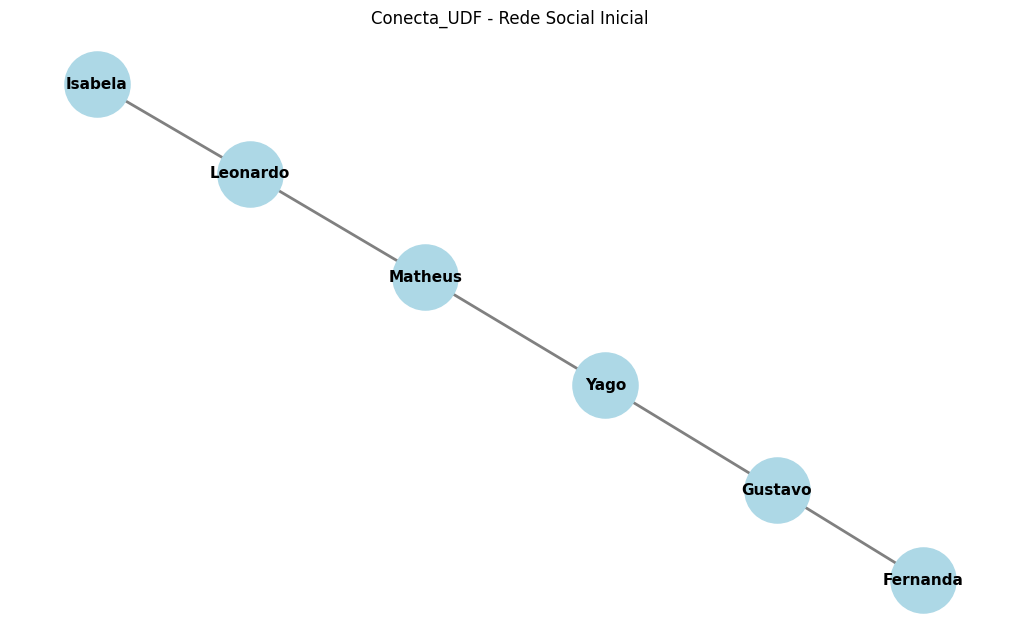

Total de usuarios: 6
Total de amizades: 5


In [2]:

import networkx as nx
import matplotlib.pyplot as plt

# Projeto Conecta_UDF
# Rede inicial com 6 usuarios e 5 amizades

rede = {
    "Yago": ["Matheus", "Gustavo"],
    "Matheus": ["Yago", "Leonardo"],
    "Gustavo": ["Yago", "Fernanda"],
    "Leonardo": ["Matheus", "Isabela"],
    "Fernanda": ["Gustavo"],
    "Isabela": ["Leonardo"]
}

grafo = nx.Graph()

for usuario, amigos in rede.items():
    for amigo in amigos:
        grafo.add_edge(usuario, amigo)

# Desenho da rede social
plt.figure(figsize=(10, 6))

posicoes = nx.spring_layout(grafo, seed=42)

nx.draw(
    grafo,
    posicoes,
    with_labels=True,
    node_color="lightblue",
    node_size=2200,
    edge_color="gray",
    font_size=11,
    font_weight="bold",
    width=2
)

plt.title("Conecta_UDF - Rede Social Inicial")
plt.axis("off")
plt.show()

print("Total de usuarios:", grafo.number_of_nodes())
print("Total de amizades:", grafo.number_of_edges())




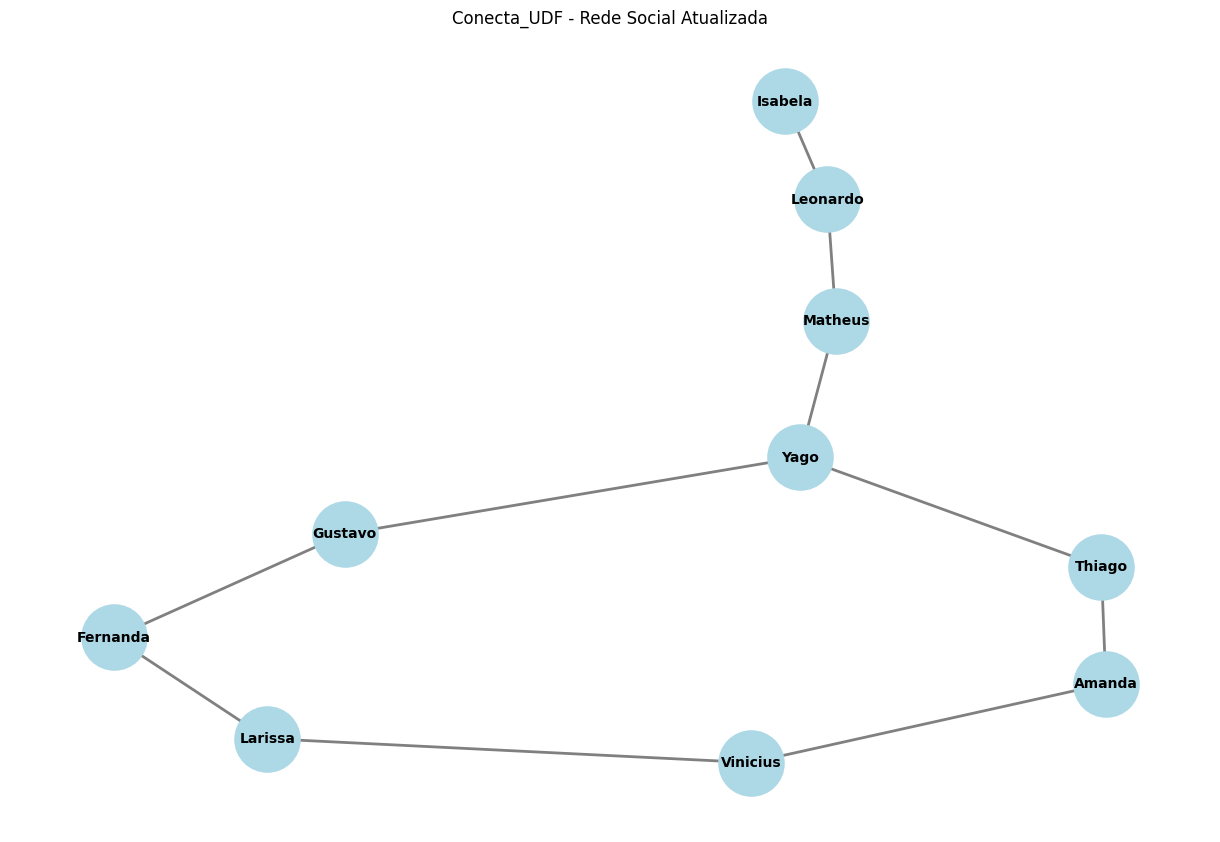

Total de usuarios: 10
Total de amizades: 10


In [3]:

# Adicionar 4 novos usuarios
novos_usuarios = [
    "Thiago", "Amanda", "Vinicius", "Larissa"
]

for usuario in novos_usuarios:
    grafo.add_node(usuario)

# Criar 5 novas amizades
novas_amizades = [
    ("Yago", "Thiago"),
    ("Thiago", "Amanda"),
    ("Amanda", "Vinicius"),
    ("Vinicius", "Larissa"),
    ("Larissa", "Fernanda")
]

for usuario1, usuario2 in novas_amizades:
    grafo.add_edge(usuario1, usuario2)

# Desenhar a rede atualizada
plt.figure(figsize=(12, 8))

posicoes = nx.spring_layout(grafo, seed=42)

nx.draw(
    grafo,
    posicoes,
    with_labels=True,
    node_color="lightblue",
    node_size=2200,
    edge_color="gray",
    font_size=10,
    font_weight="bold",
    width=2
)

plt.title("Conecta_UDF - Rede Social Atualizada")
plt.axis("off")
plt.show()

print("Total de usuarios:", grafo.number_of_nodes())
print("Total de amizades:", grafo.number_of_edges())


In [4]:

# Etapa 3 - Analise da rede social

print("=== GRAU DE CADA USUARIO ===")

for usuario in grafo.nodes():
    grau = grafo.degree(usuario)
    print(f"{usuario}: {grau} amizade(s)")

# Quantidade de usuarios e amizades
vertices = grafo.number_of_nodes()
arestas = grafo.number_of_edges()

# Soma dos graus
soma_graus = 0

for usuario in grafo.nodes():
    soma_graus += grafo.degree(usuario)

# Densidade do grafo
densidade = (2 * arestas) / (vertices * (vertices - 1))

print("\n=== RESULTADOS ===")
print("Usuarios:", vertices)
print("Soma dos graus:", soma_graus)
print("Amizades:", arestas)
print(f"Densidade: {densidade:.2%}")

# Identificar os usuarios mais conectados
maior_grau = max(dict(grafo.degree()).values())

print("\n=== USUARIOS MAIS CONECTADOS ===")

for usuario in grafo.nodes():
    if grafo.degree(usuario) == maior_grau:
        print(usuario, "-", maior_grau, "amizades")

# Encontrar menor caminho entre dois usuarios
caminho = nx.shortest_path(grafo, "Isabela", "Larissa")

print("\n=== MENOR CAMINHO ===")
print(" -> ".join(caminho))
print("Quantidade de arestas:", len(caminho) - 1)


=== GRAU DE CADA USUARIO ===
Yago: 3 amizade(s)
Matheus: 2 amizade(s)
Gustavo: 2 amizade(s)
Leonardo: 2 amizade(s)
Fernanda: 2 amizade(s)
Isabela: 1 amizade(s)
Thiago: 2 amizade(s)
Amanda: 2 amizade(s)
Vinicius: 2 amizade(s)
Larissa: 2 amizade(s)

=== RESULTADOS ===
Usuarios: 10
Soma dos graus: 20
Amizades: 10
Densidade: 22.22%

=== USUARIOS MAIS CONECTADOS ===
Yago - 3 amizades

=== MENOR CAMINHO ===
Isabela -> Leonardo -> Matheus -> Yago -> Gustavo -> Fernanda -> Larissa
Quantidade de arestas: 6


In [5]:

# Etapa 4 - Comparacao das redes

# Dados da rede inicial
usuarios_inicial = 6
amizades_inicial = 5

# Dados da rede atualizada
usuarios_final = grafo.number_of_nodes()
amizades_final = grafo.number_of_edges()

# Calculo das densidades
densidade_inicial = (2 * amizades_inicial) / (
    usuarios_inicial * (usuarios_inicial - 1)
)

densidade_final = (2 * amizades_final) / (
    usuarios_final * (usuarios_final - 1)
)

print("=== COMPARACAO DAS REDES ===")

print("\nRede inicial:")
print("Usuarios:", usuarios_inicial)
print("Amizades:", amizades_inicial)
print(f"Densidade: {densidade_inicial:.2%}")

print("\nRede atualizada:")
print("Usuarios:", usuarios_final)
print("Amizades:", amizades_final)
print(f"Densidade: {densidade_final:.2%}")

print("\n=== COMPARACAO DOS GRAUS ===")

for usuario in grafo.nodes():
    grau_inicial = len(rede[usuario]) if usuario in rede else 0
    grau_final = grafo.degree(usuario)

    print(f"{usuario}: {grau_inicial} -> {grau_final}")


=== COMPARACAO DAS REDES ===

Rede inicial:
Usuarios: 6
Amizades: 5
Densidade: 33.33%

Rede atualizada:
Usuarios: 10
Amizades: 10
Densidade: 22.22%

=== COMPARACAO DOS GRAUS ===
Yago: 2 -> 3
Matheus: 2 -> 2
Gustavo: 2 -> 2
Leonardo: 2 -> 2
Fernanda: 1 -> 2
Isabela: 1 -> 1
Thiago: 0 -> 2
Amanda: 0 -> 2
Vinicius: 0 -> 2
Larissa: 0 -> 2


In [6]:

# Etapa 5 - Analise das conexoes da rede social

print("=== AMIZADES DIRETAS ===")

for usuario in grafo.nodes():
    amigos = list(grafo.neighbors(usuario))
    print(f"{usuario}: {', '.join(amigos)}")

print("\n=== SUGESTOES DE AMIZADE ===")

for usuario in grafo.nodes():
    amigos = set(grafo.neighbors(usuario))

    for outro in grafo.nodes():
        if usuario != outro and outro not in amigos:
            amigos_do_outro = set(grafo.neighbors(outro))
            amigos_em_comum = amigos.intersection(amigos_do_outro)

            if len(amigos_em_comum) >= 2:
                print(
                    f"{usuario} pode conhecer {outro} "
                    f"por meio de {', '.join(sorted(amigos_em_comum))}"
                )

print("\n=== CENTRALIDADE DE INTERMEDIACAO ===")

centralidade = nx.betweenness_centrality(grafo)

for usuario, valor in centralidade.items():
    print(f"{usuario}: {valor:.3f}")

mais_estrategico = max(centralidade, key=centralidade.get)

print("\nUsuario mais estrategico:", mais_estrategico)


=== AMIZADES DIRETAS ===
Yago: Matheus, Gustavo, Thiago
Matheus: Yago, Leonardo
Gustavo: Yago, Fernanda
Leonardo: Matheus, Isabela
Fernanda: Gustavo, Larissa
Isabela: Leonardo
Thiago: Yago, Amanda
Amanda: Thiago, Vinicius
Vinicius: Amanda, Larissa
Larissa: Vinicius, Fernanda

=== SUGESTOES DE AMIZADE ===

=== CENTRALIDADE DE INTERMEDIACAO ===
Yago: 0.583
Matheus: 0.389
Gustavo: 0.250
Leonardo: 0.222
Fernanda: 0.167
Isabela: 0.000
Thiago: 0.250
Amanda: 0.167
Vinicius: 0.083
Larissa: 0.083

Usuario mais estrategico: Yago


In [7]:

# Tabela final de graus e calculos

import pandas as pd

dados = []

for usuario in grafo.nodes():
    grau = grafo.degree(usuario)
    dados.append([usuario, grau])

tabela = pd.DataFrame(
    dados,
    columns=["Usuario", "Quantidade de amizades"]
)

display(tabela)

# Conferencia dos resultados
vertices = grafo.number_of_nodes()
arestas = grafo.number_of_edges()
soma_graus = sum(grau for usuario, grau in grafo.degree())
densidade = 2 * arestas / (vertices * (vertices - 1))

print("\n=== CONFERENCIA FINAL ===")
print("Usuarios:", vertices)
print("Amizades:", arestas)
print("Soma dos graus:", soma_graus)
print(f"Densidade: {densidade:.2%}")

# Validar os resultados
assert vertices == 10, "Erro na quantidade de usuarios"
assert arestas == 10, "Erro na quantidade de amizades"
assert soma_graus == 2 * arestas, "Erro na soma dos graus"
assert abs(densidade - 2/9) < 1e-10, "Erro na densidade"

print("\nTodos os calculos foram validados!")


,Usuario,Quantidade de amizades
0,Yago,3
1,Matheus,2
2,Gustavo,2
3,Leonardo,2
4,Fernanda,2
5,Isabela,1
6,Thiago,2
7,Amanda,2
8,Vinicius,2
9,Larissa,2



=== CONFERENCIA FINAL ===
Usuarios: 10
Amizades: 10
Soma dos graus: 20
Densidade: 22.22%

Todos os calculos foram validados!


1. Quem é mais conectado? Isso significa que é o mais influente?
Yago possui o maior número de conexões, com três amizades. Porém, ter mais amigos não significa necessariamente ser mais influente. A influência também pode depender da posição do usuário na rede e da sua capacidade de conectar diferentes grupos.
2. Como sugerir amizade usando amigos em comum?
O sistema pode comparar as listas de amigos dos usuários e identificar pessoas que possuem conexões em comum, mas ainda não são amigas. Essas pessoas podem receber sugestões de amizade.
3. Que cuidados de privacidade são necessários?
É importante proteger os dados pessoais, permitir que os usuários controlem a visibilidade de seus perfis e evitar o compartilhamento de informações sem autorização.
4. Quais outras métricas podem descrever uma rede?
Além do grau e da densidade, podemos utilizar a centralidade de intermediação, a distância entre usuários e a quantidade de componentes conectados.

## Conclusão

Neste projeto, utilizamos grafos para representar uma rede social e analisar as conexões entre seus usuários. Inicialmente, criamos uma rede com 6 usuários e 5 amizades. Depois, adicionamos 4 novos usuários e 5 amizades, chegando a um total de 10 usuários e 10 conexões.

Com o desenvolvimento do algoritmo em Python, foi possível calcular o grau de cada usuário, a quantidade de arestas, a densidade da rede e os caminhos entre os participantes.

Observamos que a densidade diminuiu de 33,33% para 22,22%, mesmo com o aumento das amizades. Também identificamos Yago como o usuário mais conectado, com 3 amizades, e com a maior centralidade de intermediação.

O projeto permitiu compreender melhor como os grafos podem ser utilizados para representar relações entre pessoas e analisar a estrutura de uma rede social.